<a href="https://colab.research.google.com/github/mihirgohil1402-ui/Cfd-lab/blob/main/09_Lid_Driven_Cavity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 9: Lid Driven Cavity

**Name:** Mihir Gohil  |  **Roll No:** 23BME019  
**Course:** Computational Fluid Dynamics and Heat Transfer Lab (20ME406P), Department of Mechanical Engineering, PDEU


## 1. Aim
To simulate the steady laminar flow in a lid-driven square cavity at Re = 100 with the stream function–vorticity method, to study the primary vortex and the corner eddies, and to validate the solution against the benchmark of Ghia, Ghia and Shin (1982).

## 2. Problem and parameters
A square cavity is filled with an incompressible fluid. The top wall (lid) slides at constant speed and the other three walls are fixed. All walls are no-slip.

| Parameter | Symbol | Value |
|---|---|---|
| Cavity side | L | 1.0 |
| Lid speed | U_lid | 1.0 |
| Reynolds number | Re = U_lid L/ν | 100 |
| Grids studied | N × N nodes | 33, 65, 97 |
| Time step | Δt | 0.2 Re Δx² (explicit stability limit is 0.25 Re Δx²) |
| Steady-state criterion | max abs change of ψ per step | < 1e-8 |

## 3. Governing equations and method
With u = ∂ψ/∂y, v = −∂ψ/∂x and vorticity ω = ∂v/∂x − ∂u/∂y, the 2D incompressible Navier–Stokes equations become
$$\frac{\partial \omega}{\partial t} + u\frac{\partial \omega}{\partial x} + v\frac{\partial \omega}{\partial y} = \frac{1}{Re}\nabla^2\omega, \qquad \nabla^2\psi = -\omega$$
This removes the pressure and automatically satisfies continuity.

- **Vorticity transport:** explicit time marching, central differences for convection and diffusion (cell Reynolds number is below 2 on all grids).
- **Poisson equation for ψ:** solved at every step with a sparse LU factorisation computed once.
- **Boundary conditions:** ψ = 0 on all walls. Wall vorticity from Thom's formula, ω_wall = −2(ψ_adjacent − ψ_wall)/Δx² − 2U_wall/Δx, where U_wall is the tangential wall speed (1 for the lid, 0 elsewhere).

In [ ]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
import pandas as pd

Re, U_lid = 100.0, 1.0
nu = 1.0/Re

def solve_cavity(N, tol=1e-8, t_max=80.0):
    h = 1.0/(N-1)
    dt = 0.2*Re*h*h
    n = N-2
    # Poisson matrix for interior nodes:  (1/h^2) * Lap psi = -omega
    D = sp.diags([np.ones(n-1), -2*np.ones(n), np.ones(n-1)], [-1, 0, 1])
    I = sp.identity(n)
    Lap = (sp.kron(D, I) + sp.kron(I, D))/h**2
    lu = spla.splu(Lap.tocsc())
    psi = np.zeros((N, N)); om = np.zeros((N, N))
    hist = []
    t = 0.0
    while t < t_max:
        # wall vorticity (Thom)
        om[:, -1] = -2*psi[:, -2]/h**2 - 2*U_lid/h     # lid
        om[:, 0]  = -2*psi[:, 1]/h**2
        om[0, :]  = -2*psi[1, :]/h**2
        om[-1, :] = -2*psi[-2, :]/h**2
        # velocities (interior)
        u = (psi[1:-1, 2:] - psi[1:-1, :-2])/(2*h)
        v = -(psi[2:, 1:-1] - psi[:-2, 1:-1])/(2*h)
        w = om[1:-1, 1:-1]
        wx = (om[2:, 1:-1] - om[:-2, 1:-1])/(2*h)
        wy = (om[1:-1, 2:] - om[1:-1, :-2])/(2*h)
        lapw = (om[2:, 1:-1] + om[:-2, 1:-1] + om[1:-1, 2:] + om[1:-1, :-2] - 4*w)/h**2
        om[1:-1, 1:-1] = w + dt*(-u*wx - v*wy + nu*lapw)
        # Poisson for psi
        psi_new = np.zeros_like(psi)
        psi_new[1:-1, 1:-1] = lu.solve(-om[1:-1, 1:-1].ravel()).reshape(n, n)
        change = np.max(abs(psi_new - psi))
        psi = psi_new
        t += dt
        hist.append(change)
        if change < tol and t > 5:
            break
    x = np.linspace(0, 1, N)
    return x, psi, om, np.array(hist), dt, t

def velocities(psi, h):
    u = np.zeros_like(psi); v = np.zeros_like(psi)
    u[1:-1, 1:-1] = (psi[1:-1, 2:] - psi[1:-1, :-2])/(2*h)
    v[1:-1, 1:-1] = -(psi[2:, 1:-1] - psi[:-2, 1:-1])/(2*h)
    u[:, -1] = U_lid
    return u, v

# Benchmark: u-velocity along the vertical centreline (x = 0.5), Re = 100, from Ghia, Ghia and Shin (1982), Table I
ghia_y = np.array([0.0, 0.0547, 0.0625, 0.0703, 0.1016, 0.1719, 0.2813, 0.4531, 0.5, 0.6172, 0.7344, 0.8516, 0.9531, 0.9609, 0.9688, 0.9766, 1.0])
ghia_u = np.array([0.0, -0.03717, -0.04192, -0.04775, -0.06434, -0.10150, -0.15662, -0.21090, -0.20581, -0.13641, 0.00332, 0.23151, 0.68717, 0.73722, 0.78871, 0.84123, 1.0])

## 4. Run the three grids

In [ ]:
results = {}
for N in (33, 65, 97):
    x, psi, om, hist, dt, t_fin = solve_cavity(N)
    h = 1/(N-1)
    u, v = velocities(psi, h)
    mid = (N-1)//2
    u_num = np.interp(ghia_y, x, u[mid, :])
    err = np.max(abs(u_num - ghia_u))
    k = np.unravel_index(np.argmin(psi), psi.shape)
    results[N] = dict(x=x, psi=psi, om=om, u=u, v=v, hist=hist, dt=dt, t=t_fin, err=err, psimin=psi.min(), centre=(x[k[0]], x[k[1]]))
    print(f"N = {N}: dt = {dt:.4f}, steps = {len(hist)}, final time = {t_fin:.1f}, psi_min = {psi.min():.5f} at ({x[k[0]]:.3f}, {x[k[1]]:.3f}), max |u - Ghia| = {err:.4f}")

N = 33: dt = 0.0195, steps = 1078, final time = 21.1, psi_min = -0.10038 at (0.625, 0.750), max |u - Ghia| = 0.0089


N = 65: dt = 0.0049, steps = 3790, final time = 18.5, psi_min = -0.10272 at (0.609, 0.734), max |u - Ghia| = 0.0028


N = 97: dt = 0.0022, steps = 7839, final time = 17.0, psi_min = -0.10318 at (0.615, 0.740), max |u - Ghia| = 0.0039


## 5. Flow field (finest grid)

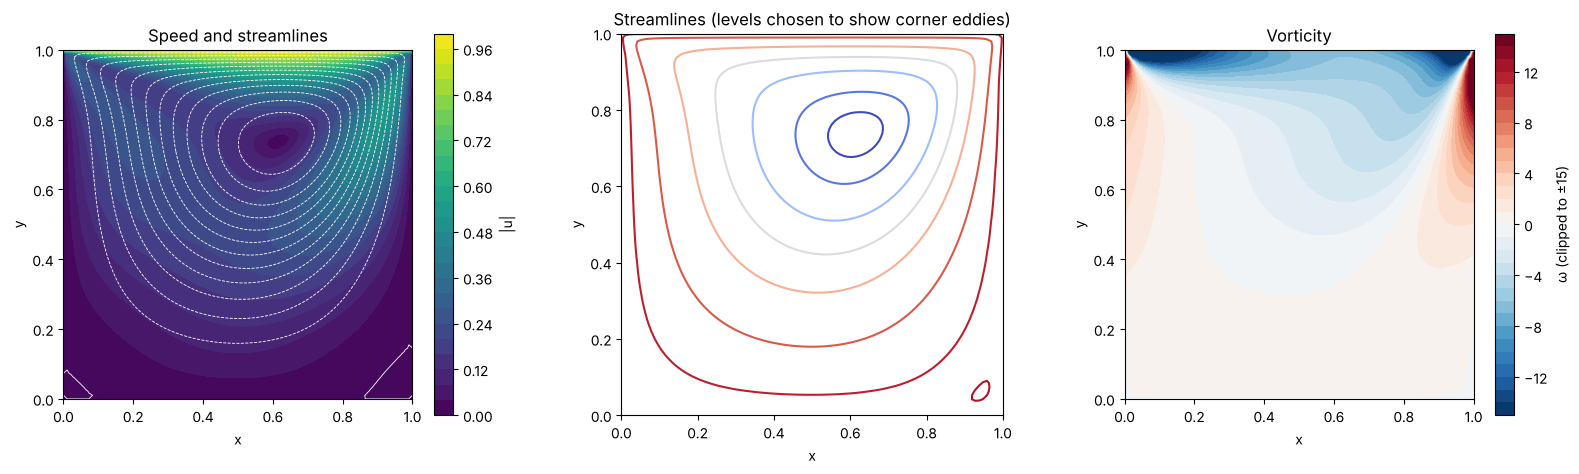

In [ ]:
N = 97
R = results[N]
X, Y = np.meshgrid(R['x'], R['x'], indexing='ij')
speed = np.sqrt(R['u']**2 + R['v']**2)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
c0 = ax[0].contourf(X, Y, speed, 30, cmap='viridis'); fig.colorbar(c0, ax=ax[0], label='|u|')
ax[0].contour(X, Y, R['psi'], 14, colors='w', linewidths=0.6)
ax[0].set(title='Speed and streamlines', xlabel='x', ylabel='y', aspect='equal')
lv = np.concatenate([[-0.1, -0.09, -0.07, -0.05, -0.03, -0.01, -0.001], [1e-5, 1e-4, 5e-4, 1e-3, 1.5e-3]])
ax[1].contour(X, Y, R['psi'], levels=np.sort(lv), cmap='coolwarm')
ax[1].set(title='Streamlines (levels chosen to show corner eddies)', xlabel='x', ylabel='y', aspect='equal')
c2 = ax[2].contourf(X, Y, np.clip(R['om'], -15, 15), 30, cmap='RdBu_r'); fig.colorbar(c2, ax=ax[2], label='ω (clipped to ±15)')
ax[2].set(title='Vorticity', xlabel='x', ylabel='y', aspect='equal')
plt.tight_layout(); plt.show()

## 6. Validation against Ghia et al. (1982) and grid study

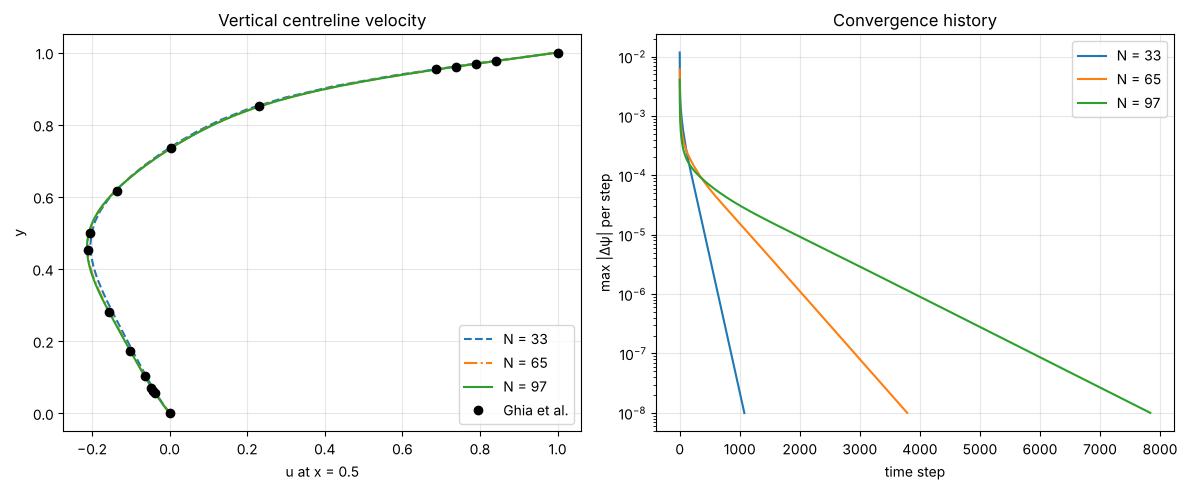

,N,dt,steps,psi_min,vortex centre,max |u − Ghia|
0,33,0.019531,1078,-0.100381,"(0.625, 0.750)",0.008893
1,65,0.004883,3790,-0.102722,"(0.609, 0.734)",0.002768
2,97,0.002170,7839,-0.103182,"(0.615, 0.740)",0.003944


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for N, mk in zip((33, 65, 97), ('--', '-.', '-')):
    R = results[N]; mid = (N-1)//2
    ax[0].plot(R['u'][mid, :], R['x'], mk, label=f'N = {N}')
ax[0].plot(ghia_u, ghia_y, 'ko', label='Ghia et al.')
ax[0].set(xlabel='u at x = 0.5', ylabel='y', title='Vertical centreline velocity'); ax[0].legend(); ax[0].grid(alpha=0.3)
for N in (33, 65, 97):
    ax[1].semilogy(results[N]['hist'], label=f'N = {N}')
ax[1].set(xlabel='time step', ylabel='max |Δψ| per step', title='Convergence history'); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

pd.DataFrame([[N, results[N]['dt'], len(results[N]['hist']), results[N]['psimin'],
               f"({results[N]['centre'][0]:.3f}, {results[N]['centre'][1]:.3f})", results[N]['err']] for N in results],
             columns=['N', 'dt', 'steps', 'psi_min', 'vortex centre', 'max |u − Ghia|'])